# Brain Tumour Segmentation with U-Net (Trained from Scratch)

This notebook trains a U-Net, implemented from scratch in PyTorch, to segment brain tumours in MRI scans. For each MRI image, the model predicts a binary mask that marks the tumour pixels.

| Component | Choice |
|---|---|
| Task | Binary semantic segmentation (tumour vs. background) |
| Dataset | Brain Tumor Segmentation (Kaggle): 3,064 MRI images with binary masks |
| Model | U-Net built from scratch, randomly initialised (no pretrained weights) |
| Loss | Binary Cross-Entropy with logits |
| Optimiser | AdamW (lr = 1e-3) with ReduceLROnPlateau |
| Metric | Intersection over Union (IoU / Jaccard Index) |
| Training | Up to 100 epochs with early stopping and best-model checkpointing |

## 1. Install Dependencies

Installs the required libraries with pinned versions so the notebook runs consistently:

- **albumentations:** image augmentation that applies the same transform to an image and its mask.
- **torchmetrics:** ready-made evaluation metrics, used here for IoU.
- **segmentation-models-pytorch** and **timm:** segmentation and backbone libraries. They are installed but not used by the from-scratch model.

In [1]:
!pip install -q segmentation-models-pytorch==0.3.1
!pip install -q timm==0.4.12
!pip install -q albumentations==1.3.0
!pip install -q torchmetrics==0.11.4

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## 2. Imports and Setup

Imports the libraries used throughout the notebook and prepares the environment.

- **Reproducibility:** the random seed is fixed for Python, NumPy and PyTorch, so data splits, augmentations and weight initialisation are repeatable.
- **Device:** the GPU (`cuda`) is used if available, otherwise the CPU.

In [2]:
import os, random, math, glob
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.functional as TF

import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp
import torchmetrics

#reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
  torch.cuda.manual_seed_all(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device: ", DEVICE)

/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/imports.py:22: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution


Device:  cuda


## 3. Download the Dataset

### 3.1 Upload the Kaggle API key

Opens a file picker to upload `kaggle.json`, which contains the Kaggle username and API key needed to download datasets.

In [3]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"rajaaqeeltariq","key":"KGAT_efa8102f8f07f1985744c84ad1cd758a"}\r\n'}

### 3.2 Configure Kaggle credentials

Copies `kaggle.json` to `/root/.kaggle/`, where the Kaggle CLI expects it, and restricts its permissions (`chmod 600`) so only the owner can read the key.

In [4]:
os.makedirs('/root/.kaggle', exist_ok=True)
!cp kaggle.json /root/.kaggle/
!chmod 600 /root/.kaggle/kaggle.json

### 3.3 Download the dataset

Downloads the Brain Tumor Segmentation dataset as a zip file. It contains MRI images and a binary mask for each image, where white pixels mark the tumour.

In [5]:
!kaggle datasets download -d nikhilroxtomar/brain-tumor-segmentation

Dataset URL: https://www.kaggle.com/datasets/nikhilroxtomar/brain-tumor-segmentation
License(s): unknown
100% 312M/312M [00:16<00:00, 19.6MB/s]



### 3.4 Extract the dataset

Unzips the archive into `/content/Dataset`.

In [6]:
!mkdir -p /content/dataset
!unzip -q brain-tumor-segmentation.zip -d /content/Dataset

### 3.5 Verify the folder structure

Defines the paths to the `images/` and `masks/` folders and checks that both exist before continuing.

In [7]:
DATA_ROOT = Path("/content/Dataset")

images_dir = DATA_ROOT / 'images'
masks_dir = DATA_ROOT /'masks'

print("Images exists: ", images_dir.exists())
print("Masks exists: ", masks_dir.exists())

sample_images = list(images_dir.glob("*"))[:6]
print("Sample images count:", len(sample_images))

Images exists:  True
Masks exists:  True
Sample images count: 6


## 4. Dataset Class and Transforms

**`BrainTumorSegDataset`** loads one image–mask pair at a time:
1. Reads the MRI image as RGB and the mask as grayscale.
2. Binarises the mask (`> 127` → 1, otherwise 0), so each pixel is either tumour or background.
3. Applies the transforms to the image and mask together, keeping them aligned.
4. Returns the image tensor and a mask tensor of shape `(1, H, W)`.

This class is redefined in the training section (Section 8), and that corrected version is the one used for training.

**Transforms**
- `train_transform` resizes images to 256×256 and applies augmentation: horizontal/vertical flips, 90° rotations, small shifts/scales/rotations, and brightness/contrast changes. Augmentation increases the variety of training data and reduces overfitting.
- `valid_transform` only resizes and normalises, so validation is performed on unaltered images.
- `Normalize()` scales pixel values to a standard range, and `ToTensorV2()` converts arrays to PyTorch tensors.

In [8]:
class BrainTumorSegDataset(Dataset):
  def __init__(self, image_paths, mask_path, transforms=None):
    self.image_paths = image_paths
    self.mask_path = mask_path
    self.transforms = transforms

  def __len__(self):
    return len(self.image_paths)

  def __getitem__(self, idx):
    img = np.array(Image.open(self.image_paths[idx]).convert("RGB"))
    mask = np.array(Image.open(self.mask_path[idx]).convert("L"))
    mask = (mask > 127).astype("float32")
    if self.transforms:
      augmented = self.transforms(image=img, mask=mask)
      img = augmentations["image"]
      mask = augmentations["mask"].unsqueeze(0)
    else:
      img = TF.to_tensor(img)
      mask = torch.tensor(mask).unsqueeze(0)
    return img, mask

train_transform = A.Compose([
    A.Resize(256,256),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1, rotate_limit=15, p=0.5),
    A.RandomBrightnessContrast(p=0.4),
    A.Normalize(),
    ToTensorV2()
])
valid_transform = A.Compose([
    A.Resize(256,256),
    A.Normalize(),
    ToTensorV2()
])

## 5. Train/Validation Split and DataLoaders

1. Pairs each image with its mask, which shares the same file name.
2. Splits the data into 85% training and 15% validation using a fixed random seed.
3. Wraps each split in the dataset class with the matching transforms.
4. Creates DataLoaders that feed the model batches of 8 images.

In [9]:
all_images = sorted(list(images_dir.glob("*")))
all_masks = [masks_dir / img.name for img in all_images]

from sklearn.model_selection import  train_test_split
train_imgs, val_imgs, train_masks, val_masks = train_test_split(
    all_images, all_masks, test_size=0.15, random_state=SEED)

train_ds = BrainTumorSegDataset(train_imgs, train_masks, transforms = train_transform)
val_ds = BrainTumorSegDataset(val_imgs, val_masks, transforms = valid_transform)

BATCH_SIZE = 8
train_loader = DataLoader(train_ds, batch_size = BATCH_SIZE, shuffle = True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size = BATCH_SIZE, shuffle = True, num_workers=2, pin_memory=True)

print("Train batch", len(train_loader), "val batches:", len(val_loader))

Train batch 326 val batches: 58


## 6. Exploratory Data Analysis (EDA)

### 6.1 Dataset statistics

Prints the dataset size and the train/validation split. It then calculates the **tumour area ratio** (the fraction of pixels belonging to the tumour) for the first 200 masks and plots its distribution.

Tumours occupy only a small part of each image, so background pixels greatly outnumber tumour pixels. This class imbalance is important to keep in mind when choosing the loss function and evaluating the model.

Total images: 3064
Train: 2604 | Val: 460


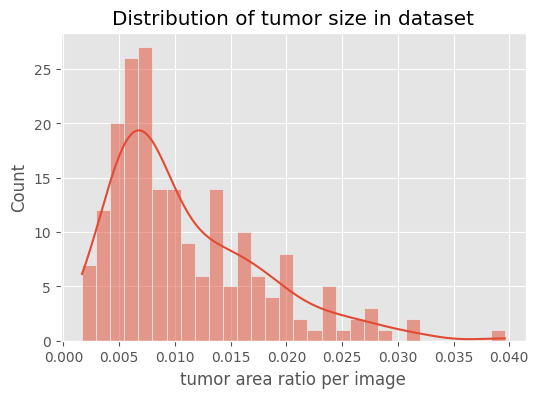

Mean tumor coverage:  1.10%


In [10]:
import cv2
import seaborn as sns
from PIL import Image
plt.style.use("ggplot")

print(f"Total images: {len(all_images)}")
print(f"Train: {len(train_imgs)} | Val: {len(val_imgs)}")

tumor_pixels = []
for m in all_masks[:200]:
    mask = np.array(Image.open(m).convert("L"))
    mask_bin = (mask > 127).astype(np.uint8)
    ratio = mask_bin.sum() / mask_bin.size
    tumor_pixels.append(ratio)

plt.figure(figsize=(6,4))
sns.histplot(tumor_pixels, bins=30, kde=True)
plt.xlabel("tumor area ratio per image")
plt.ylabel("Count")
plt.title("Distribution of tumor size in dataset")
plt.show()

print(f"Mean tumor coverage: {np.mean(tumor_pixels)*100: .2f}%")

### 6.2 Visualise random samples

Displays 6 random MRI images alongside the same images with the tumour mask overlaid in red. This confirms that images and masks are correctly paired, and shows the variation in tumour size, shape and location.

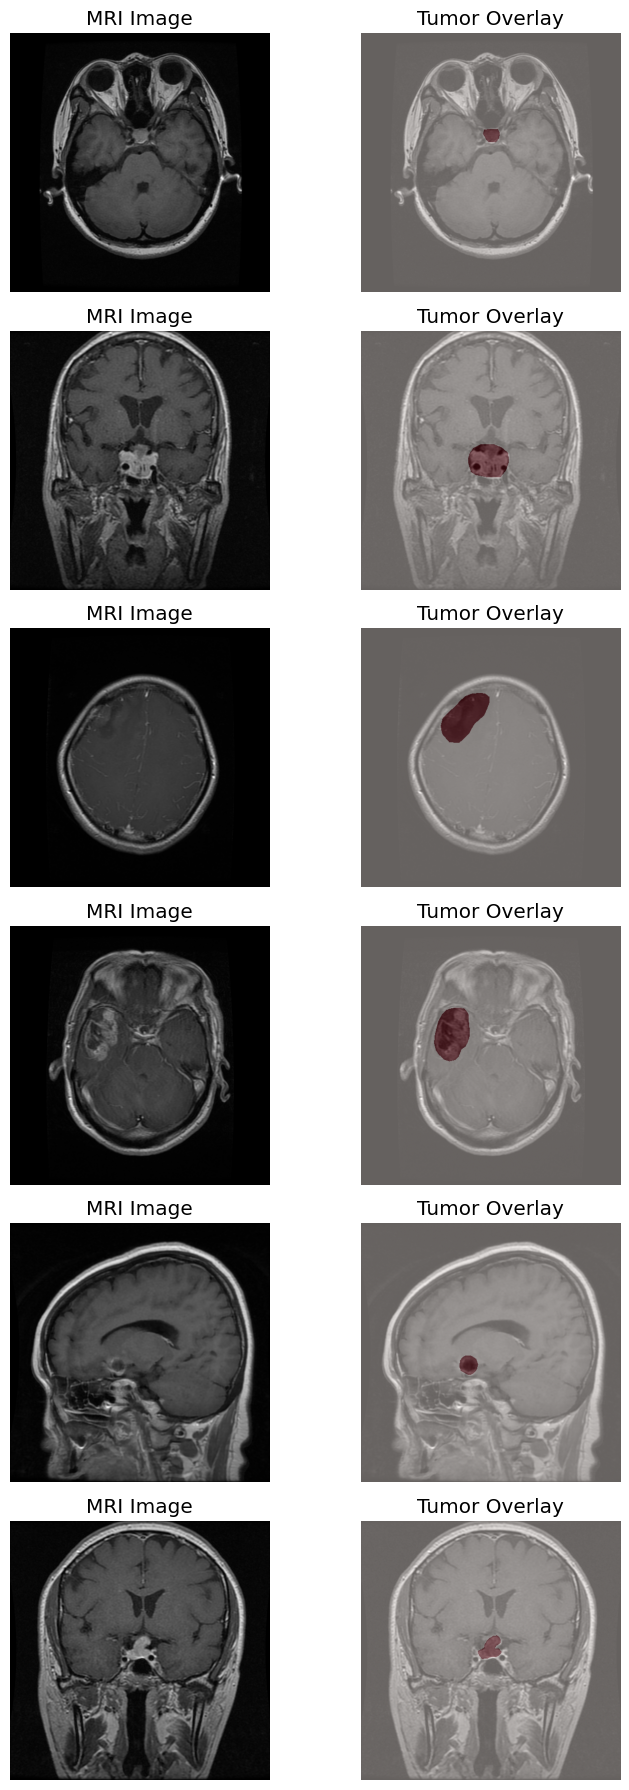

In [11]:
from PIL import Image

n_samples = 6
fig, axs = plt.subplots(n_samples, 2,  figsize=(8, 3*n_samples))
for i in range(n_samples):
    idx = random.randint(0, len(train_imgs)-1)
    img = np.array(Image.open(all_images[idx]).convert("RGB"))
    mask = np.array(Image.open(all_masks[idx]).convert("L"))
    mask_bin = (mask > 127).astype(np.uint8)
    axs[i, 0].imshow(img)
    axs[i, 0].set_title("MRI Image")
    axs[i, 1].axis("off")
    axs[i, 1].imshow(img)
    axs[i, 1].imshow(mask_bin, cmap="Reds", alpha=0.4)
    axs[i, 1].set_title("Tumor Overlay")
    axs[i, 0].axis("off")

plt.tight_layout()
plt.show()

## 7. U-Net Model (from Scratch)

### 7.1 Model architecture

**`DoubleConv`** is the basic building block of U-Net: two 3×3 convolutions, each followed by Batch Normalisation and ReLU.

**`UNet`** consists of three parts:
- **Encoder (contracting path):** four `DoubleConv` blocks with 64, 128, 256 and 512 filters. Each is followed by 2×2 max pooling, which halves the spatial size while increasing the number of feature channels. This captures *what* is in the image.
- **Bottleneck:** a `DoubleConv` block with 1024 filters at the lowest resolution.
- **Decoder (expanding path):** four transposed convolutions that double the spatial size. Each upsampled output is **concatenated with the matching encoder output (skip connection)**, then passed through a `DoubleConv`. Skip connections restore fine spatial detail lost during downsampling, which is what allows precise tumour boundaries.
- **Output head:** a 1×1 convolution that produces one channel of raw scores (logits) per pixel. The sigmoid is applied later.

The model is initialised with random weights (no pretraining). The sanity check passes a dummy 256×256 image through the network to confirm the output shape `(1, 1, 256, 256)` and prints the number of trainable parameters.

In [12]:
class DoubleConv(nn.Module):
    """(Conv 3x3 -> BatchNorm -> ReLU) x 2"""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True))
    def forward(self, x):
        return self.net(x)

class UNet(nn.Module):
    def __init__(self, in_ch=3, out_ch=1, features=(64, 128, 256, 512)):
        super().__init__()
        self.downs, self.ups = nn.ModuleList(), nn.ModuleList()
        self.pool = nn.MaxPool2d(2)
        # Encoder
        for f in features:
            self.downs.append(DoubleConv(in_ch, f)); in_ch = f
        # Bottleneck
        self.bottleneck = DoubleConv(features[-1], features[-1] * 2)
        # Decoder
        for f in reversed(features):
            self.ups.append(nn.ConvTranspose2d(f * 2, f, 2, stride=2))
            self.ups.append(DoubleConv(f * 2, f))
        self.head = nn.Conv2d(features[0], out_ch, 1)

    def forward(self, x):
        skips = []
        for down in self.downs:
            x = down(x); skips.append(x); x = self.pool(x)
        x = self.bottleneck(x)
        for i in range(0, len(self.ups), 2):
            x = self.ups[i](x)                              # upsample
            x = torch.cat([skips.pop(), x], dim=1)          # skip connection
            x = self.ups[i + 1](x)                          # DoubleConv
        return self.head(x)                                 # raw logits

model = UNet(in_ch=3, out_ch=1).to(DEVICE)

# Sanity check
print(model(torch.randn(1, 3, 256, 256).to(DEVICE)).shape)   # torch.Size([1, 1, 256, 256])
print(f"Parameters: {sum(p.numel() for p in model.parameters())/1e6:.1f}M")

torch.Size([1, 1, 256, 256])
Parameters: 31.0M


### 7.2 Optimiser and learning-rate scheduler

- **AdamW** updates the model weights with a learning rate of 1e-3.
- **ReduceLROnPlateau** halves the learning rate when the validation loss has not improved for 3 epochs, allowing finer updates later in training.

The model is re-created in this cell so that the optimiser is linked to the parameters of the model being trained. If the optimiser points to a different model instance, the weights are never updated.

In [13]:
model = UNet(in_ch=3, out_ch=1).to(DEVICE)

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=3
)

## 8. Training and Validation

**Loss and metric**
- **`BCEWithLogitsLoss`** (Binary Cross-Entropy) compares the predicted probability of each pixel with its true label. It applies the sigmoid internally, which is why the model outputs raw logits.
- **`BinaryJaccardIndex`** computes IoU: the overlap between the predicted and true masks divided by their union. A score of 1.0 means a perfect match.

**Dataset and DataLoaders:** the dataset class is redefined so every mask has the shape `(1, H, W)` expected by the loss. The training loader shuffles data each epoch, while the validation loader keeps a fixed order.

**`train_one_epoch`** passes over the training data once. For each batch it runs a forward pass, computes the loss, backpropagates and updates the weights. It returns the average loss per image.

**`validate_one_epoch`** evaluates the model without updating it. It converts predictions to probabilities with sigmoid, thresholds them at 0.5 to obtain binary masks, and computes the IoU of each image before averaging.

**Training loop**
- Runs for up to 100 epochs, recording training loss, validation loss and validation IoU.
- **Checkpointing:** whenever validation IoU improves, the model weights are saved to `unet_scratch_best.pt`.
- **Early stopping:** training stops if validation IoU does not improve for 12 consecutive epochs, preventing wasted computation and overfitting.
- After training, the **best saved weights are reloaded**, so all later evaluation uses the best model rather than the last epoch.

**Learning curves:** the loss plot compares training and validation loss over epochs, and the IoU plot shows how segmentation quality improves during training.

Epoch 1/100


Train:   0%|          | 0/326 [00:00<?, ?it/s]

Val:   0%|          | 0/58 [00:00<?, ?it/s]

Train Loss: 0.1169 | Val Loss: 0.0684 | Val IOU: 0.0128
saved new best model
Epoch 2/100


Train:   0%|          | 0/326 [00:00<?, ?it/s]

Val:   0%|          | 0/58 [00:00<?, ?it/s]

... (126 outputs left out)

Train Loss: 0.0125 | Val Loss: 0.0147 | Val IOU: 0.7050
Epoch 45/100


Train:   0%|          | 0/326 [00:00<?, ?it/s]

Val:   0%|          | 0/58 [00:00<?, ?it/s]

Train Loss: 0.0123 | Val Loss: 0.0146 | Val IOU: 0.7094
Early stopping at epoch 45. Best Val IoU: 0.7111
Loaded best model (Val IoU: 0.7111)


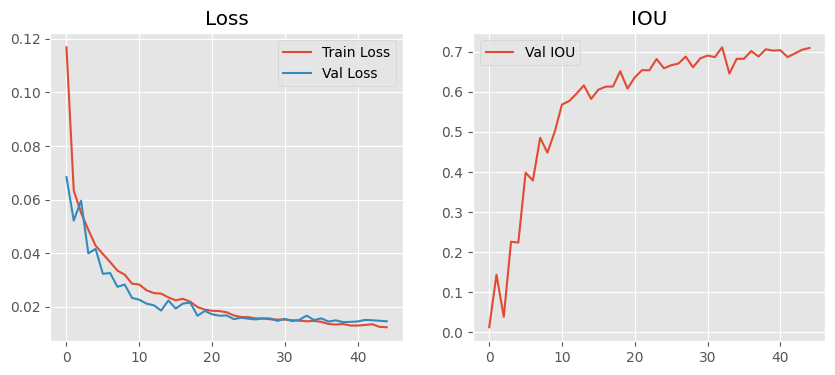

In [17]:
from tqdm.auto import tqdm
import torchmetrics

# ---------------- Define loss function and IoU metric ----------------
loss_fn = nn.BCEWithLogitsLoss()
metric_iou = torchmetrics.classification.BinaryJaccardIndex().to(DEVICE)

# ---------------- Dataset class (mask always has shape (1, H, W)) ----------------
class BrainTumorSegDataset(Dataset):
    def __init__(self, image_paths, mask_path, transforms=None):
        self.image_paths = image_paths
        self.mask_path = mask_path
        self.transforms = transforms

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img = np.array(Image.open(self.image_paths[idx]).convert("RGB"))
        mask = np.array(Image.open(self.mask_path[idx]).convert("L"))
        mask = (mask > 127).astype("float32")
        if self.transforms:
            augmented = self.transforms(image=img, mask=mask)
            img = augmented["image"]
            mask = augmented["mask"]
            if mask.ndim == 2:
                mask = mask.unsqueeze(0)
        else:
            img = TF.to_tensor(img)
            mask = torch.tensor(mask).unsqueeze(0)
        return img, mask

# ---------------- Datasets and DataLoaders ----------------
train_ds = BrainTumorSegDataset(train_imgs, train_masks, transforms=train_transform)
val_ds = BrainTumorSegDataset(val_imgs, val_masks, transforms=valid_transform)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=2, pin_memory=True, persistent_workers=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=2, pin_memory=True, persistent_workers=True)

# ---------------- Training and validation functions ----------------
def train_one_epoch(loader, model, optimizer):
    model.train()
    running_loss = 0.0
    for imgs, masks in tqdm(loader, desc="Train"):
        imgs = imgs.to(DEVICE)
        masks = masks.to(DEVICE)
        preds = model(imgs)
        loss = loss_fn(preds, masks)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * imgs.size(0)
    return running_loss / len(loader.dataset)

def validate_one_epoch(loader, desc="Val"):
    model.eval()
    running_loss = 0.0
    iou_score = 0.0
    with torch.no_grad():
        for imgs, masks in tqdm(loader, desc=desc):
            imgs = imgs.to(DEVICE)
            masks = masks.to(DEVICE)
            preds = model(imgs)
            loss = loss_fn(preds, masks)
            running_loss += loss.item() * imgs.size(0)
            probs = torch.sigmoid(preds)
            preds_bin = (probs > 0.5).int()
            masks_int = masks.int()
            for p, t in zip(preds_bin, masks_int):
                iou_score += metric_iou(p, t).item()
    avg_loss = running_loss / len(loader.dataset)
    avg_iou = iou_score / len(loader.dataset)
    return avg_loss, avg_iou

# ---------------- Training loop with checkpointing + early stopping ----------------
EPOCHS = 100
PATIENCE = 12
best_iou, wait = 0.0, 0
history = {"train_loss": [], "val_loss": [], "val_iou": []}

for epoch in range(1, EPOCHS + 1):
    print(f"Epoch {epoch}/{EPOCHS}")
    tr_loss = train_one_epoch(train_loader, model, optimizer)
    val_loss, val_iou = validate_one_epoch(val_loader)
    scheduler.step(val_loss)

    history["train_loss"].append(tr_loss)
    history["val_loss"].append(val_loss)
    history["val_iou"].append(val_iou)
    print(f"Train Loss: {tr_loss:.4f} | Val Loss: {val_loss:.4f} | Val IOU: {val_iou:.4f}")

    if val_iou > best_iou:
        best_iou, wait = val_iou, 0
        torch.save(model.state_dict(), "unet_scratch_best.pt")
        print("saved new best model")
    else:
        wait += 1
        if wait >= PATIENCE:
            print(f"Early stopping at epoch {epoch}. Best Val IoU: {best_iou:.4f}")
            break

# Load the best weights for evaluation and visualisation
model.load_state_dict(torch.load("unet_scratch_best.pt"))
print(f"Loaded best model (Val IoU: {best_iou:.4f})")

# ---------------- Learning curves ----------------
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history["train_loss"], label="Train Loss")
plt.plot(history["val_loss"], label="Val Loss")
plt.legend(); plt.title("Loss")
plt.subplot(1, 2, 2)
plt.plot(history["val_iou"], label="Val IOU")
plt.legend(); plt.title("IOU")
plt.show()

## 9. Visualising Predictions

**`overlay_mask_on_image`** colours the predicted tumour pixels red and blends them onto the MRI image.

For 6 validation images, each row shows the MRI image, the ground-truth mask, and the model's prediction overlaid in red. This allows a direct visual comparison between what the model predicted and the true tumour region.

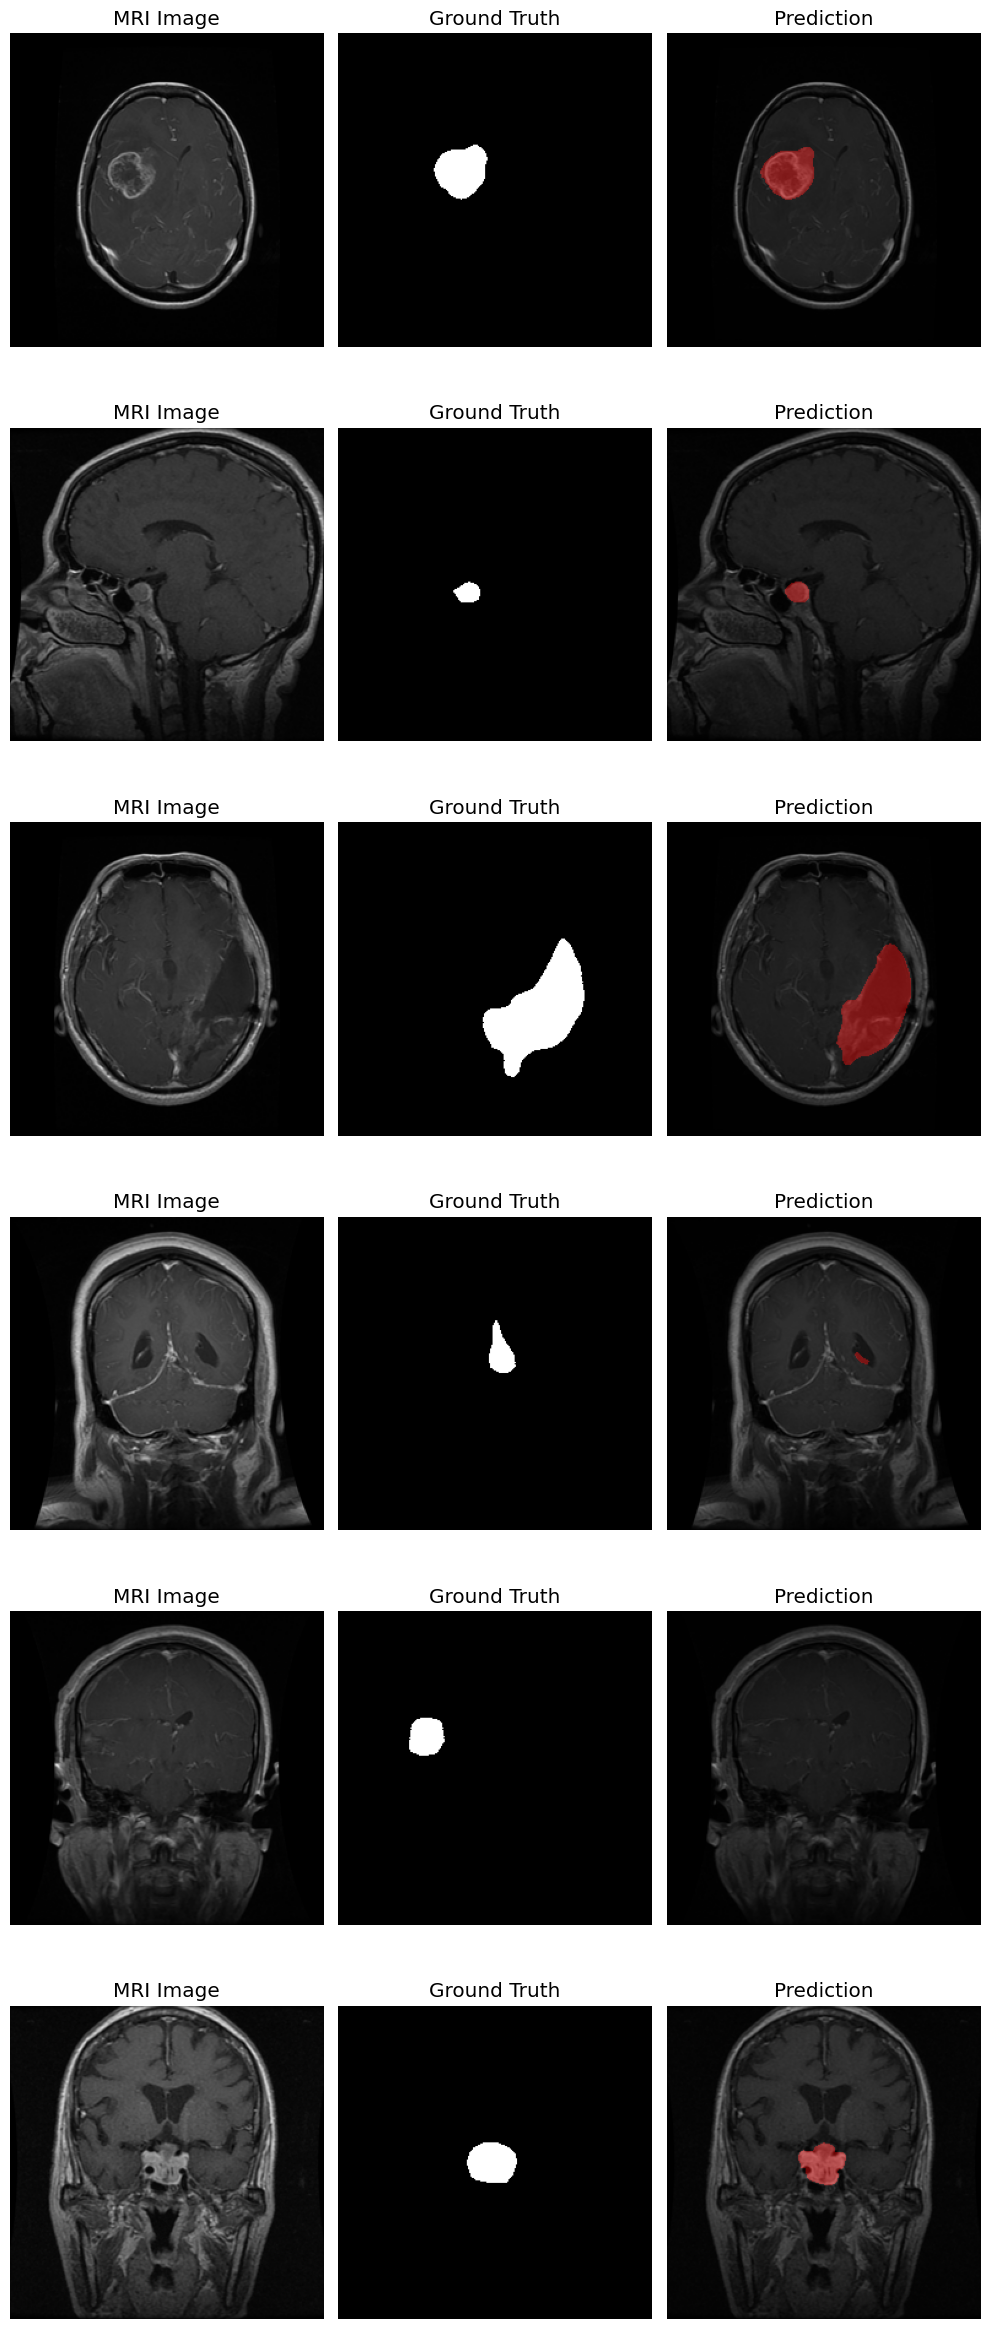

In [18]:
def overlay_mask_on_image(image, mask, alpha=0.4):
  img = image.copy()
  mask_color = np.zeros_like(img)
  mask_color[...,0] = (mask * 255).astype(np.uint8)
  overlay = cv2.addWeighted(img, 1-alpha, mask_color, alpha, 0)
  return overlay

model.eval()
n_show = 6
fig, axs = plt.subplots(n_show, 3, figsize=(10, 4*n_show))
for i in range(n_show):
  img_path = val_imgs[i]
  mask_path = val_masks[i]
  img_np = np.array(Image.open(img_path).convert("RGB").resize((256,256)))
  mask_np = np.array(Image.open(mask_path).convert("L").resize((256,256))) > 127
  input_t = valid_transform(image=img_np)["image"].unsqueeze(0).to(DEVICE)
  with torch.no_grad():
    pred = model(input_t)
    pred_prob = torch.sigmoid(pred).squeeze().cpu().numpy()
    pred_bin = pred_prob > 0.5

  overlay = overlay_mask_on_image(img_np, pred_bin)
  axs[i, 0].imshow(img_np); axs[i, 0].set_title("MRI Image"); axs[i, 0].axis("off")
  axs[i, 1].imshow(mask_np, cmap='gray'); axs[i, 1].set_title("Ground Truth"); axs[i, 1].axis("off")
  axs[i, 2].imshow(overlay); axs[i, 2].set_title("Prediction"); axs[i, 2].axis("off")

plt.tight_layout()
plt.show()

## 10. Extended Visualisation: Heatmaps and Contours

For 12 validation images, each row shows four panels:

1. **Original MRI:** the input image.
2. **Ground Truth Mask:** the annotated tumour region.
3. **Prediction Probability (Heatmap):** the sigmoid output before thresholding. Brighter regions indicate higher confidence that a pixel is tumour.
4. **Predicted Contours (green):** the outline of the thresholded prediction, drawn on the MRI with `cv2.findContours`, making the predicted boundary easy to compare with the real tumour.

The heatmap shows how confident the model is in each region, not only its final decision.

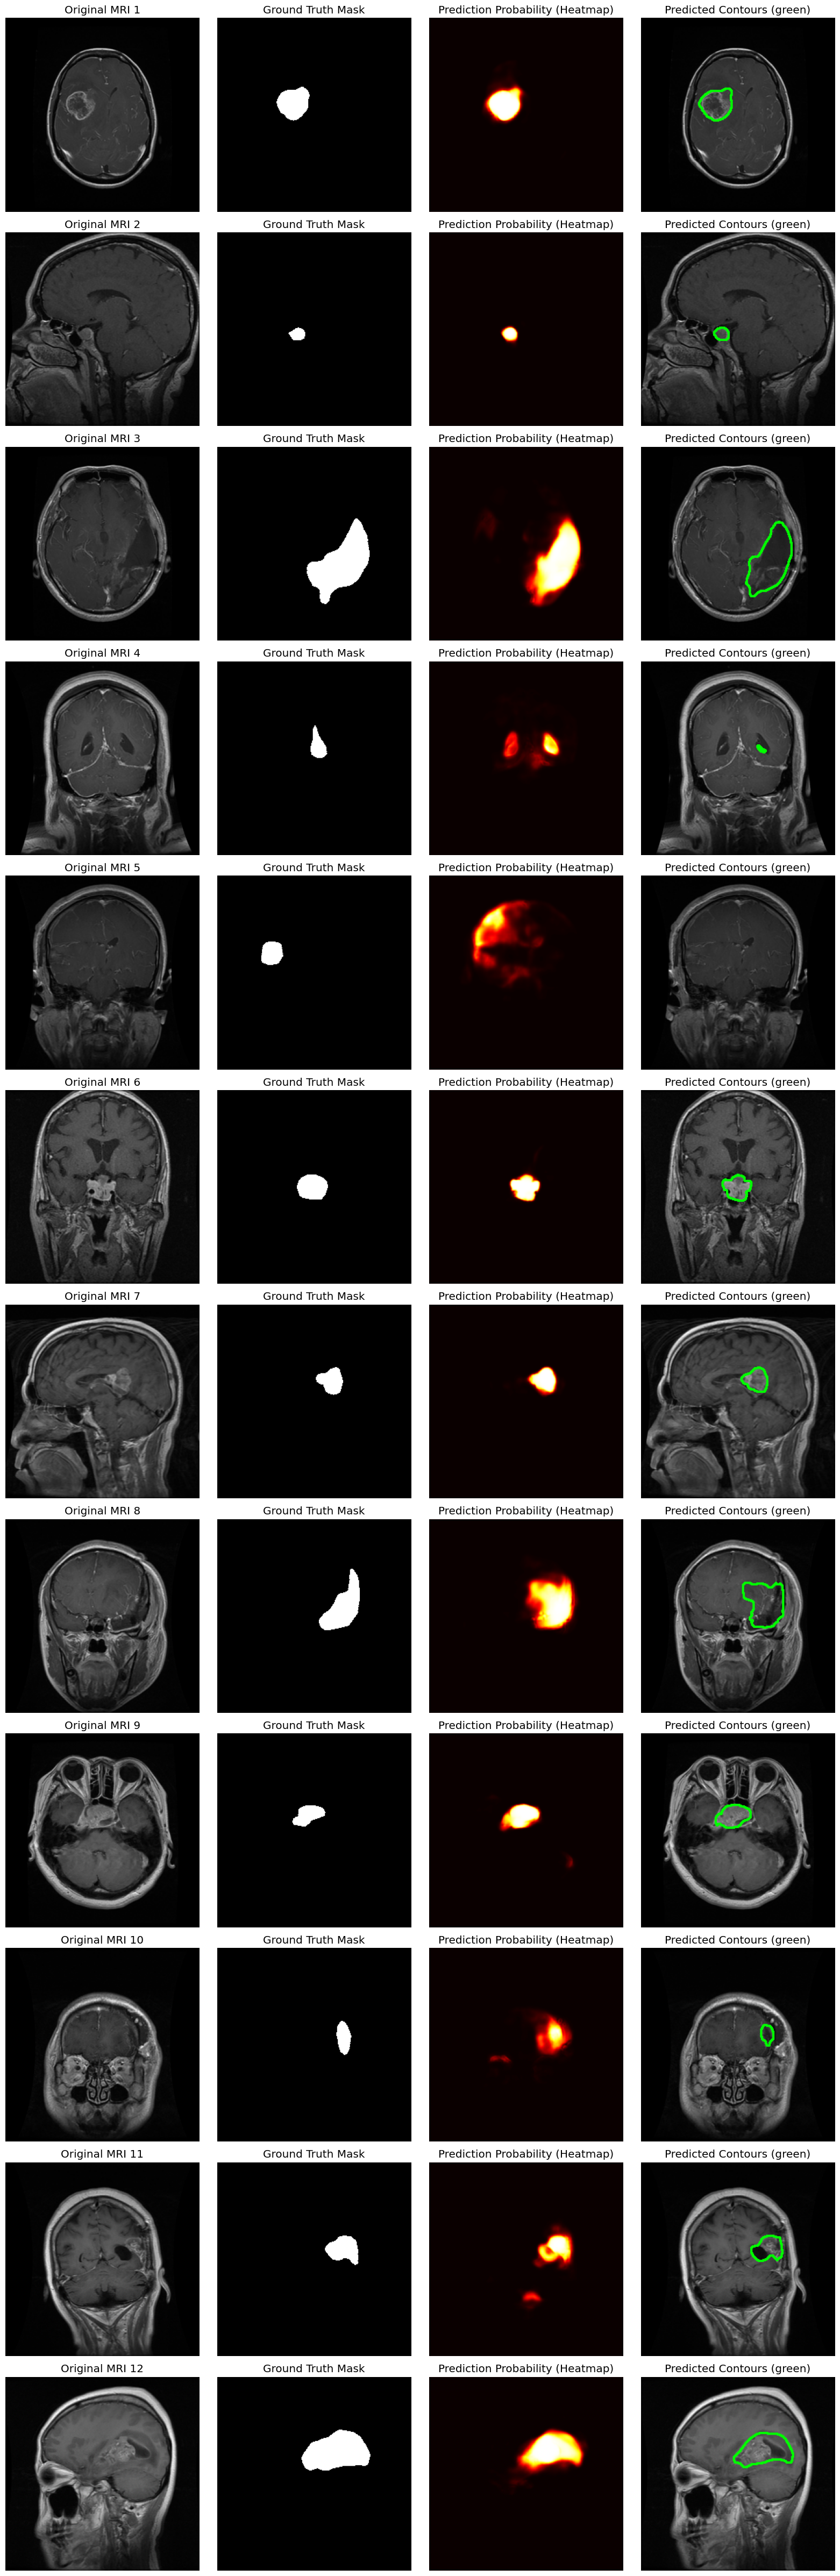

In [19]:
import matplotlib.patches as patches

def visualize_predictions(model, img_paths, mask_paths, n_samples=12):
    model.eval()
    fig, axs = plt.subplots(n_samples, 4, figsize=(16, 4*n_samples))

    for i in range(n_samples):
        img_path = img_paths[i]
        mask_path = mask_paths[i]

        img_np = np.array(Image.open(img_path).convert("RGB").resize((256,256)))
        mask_np = np.array(Image.open(mask_path).convert("L").resize((256,256))) > 127

        input_t = valid_transform(image=img_np)["image"].unsqueeze(0).to(DEVICE)
        with torch.no_grad():
            pred = model(input_t)
            pred_prob = torch.sigmoid(pred).squeeze().cpu().numpy()
            pred_bin = pred_prob > 0.5

        overlay_pred = overlay_mask_on_image(img_np, pred_bin)

        contours, _ = cv2.findContours(pred_bin.astype("uint8"), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        contour_img = img_np.copy()
        cv2.drawContours(contour_img, contours, -1, (0,255,0), 2)

        axs[i,0].imshow(img_np)
        axs[i,0].set_title(f"Original MRI {i+1}")
        axs[i,0].axis("off")

        axs[i,1].imshow(mask_np, cmap="gray")
        axs[i,1].set_title("Ground Truth Mask")
        axs[i,1].axis("off")

        axs[i,2].imshow(pred_prob, cmap="hot")
        axs[i,2].set_title("Prediction Probability (Heatmap)")
        axs[i,2].axis("off")

        axs[i,3].imshow(contour_img)
        axs[i,3].set_title("Predicted Contours (green)")
        axs[i,3].axis("off")

    plt.tight_layout()
    plt.show()


visualize_predictions(model, val_imgs, val_masks, n_samples=12)